In [24]:
import pandas as pd
import os
import numpy as np
from collections import Counter
from scipy.stats import skew
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import savgol_filter

In [25]:
data = pd.read_csv(r'..\2. Exploratory Data Analyst\Data_HasTarget_NotPreocess.csv')

# Chuyển sang datetime
data['time'] = pd.to_datetime(data['time'], errors='coerce')

# Dòng vi phạm khoảng cách < 1h
diff_not_1h = (data['time'].diff() < pd.Timedelta(hours=1)).tolist()
print(data.shape, len(diff_not_1h))

# Đảo flag để giữ các dòng hợp lệ
data = data[[not flag for flag in diff_not_1h]].copy()
print(data.shape, len(diff_not_1h))

diff_not_1h = (data['time'].diff() != pd.Timedelta(hours=1)).tolist()
if any(diff_not_1h):
    print("Vẫn còn những dòng vi phạm <1h!")
else:
    print("Không còn dòng vi phạm <1h.")

(35087, 18) 35087
(35061, 18) 35087
Vẫn còn những dòng vi phạm <1h!


In [26]:
print(data.shape)
data.head()

(35061, 18)


,time,temp,weather,wind,RH,P,co,no,no2,o3,so2,nh3,pm2_5_next1,pm10_next1,pm2_5_next2,pm10_next2,pm2_5_next3,pm10_next3
0,2021-09-01 00:00:00,26.0,Passing clouds.,4.0,94.0,1010.0,5607.61,110.87,52.09,0.0,112.53,45.60,279.26,321.64,280.09,316.42,267.37,299.51
1,2021-09-01 01:00:00,26.0,Passing clouds.,2.0,94.0,1009.0,5554.20,118.02,55.52,0.0,118.26,42.56,280.09,316.42,267.37,299.51,248.21,276.38
2,2021-09-01 02:00:00,26.0,Passing clouds.,2.0,94.0,1009.0,5233.76,121.59,58.95,0.0,122.07,39.01,267.37,299.51,248.21,276.38,228.91,254.06
3,2021-09-01 03:00:00,26.0,Passing clouds.,2.0,94.0,1008.0,4646.30,116.23,63.06,0.0,123.98,33.95,248.21,276.38,228.91,254.06,218.71,243.63
4,2021-09-01 04:00:00,26.0,Passing clouds.,0.0,94.0,1009.0,3898.62,101.92,63.75,0.0,108.72,24.32,228.91,254.06,218.71,243.63,212.32,238.87


In [27]:
cols_in_ordered = ['time', 'temp', 'weather', 'wind', 'RH', 'P', 'co', 'no', 'no2', 'o3', 'so2', 'nh3', 'pm2_5_next1', 
                   'pm10_next1', 'pm2_5_next2', 'pm10_next2', 'pm2_5_next3', 'pm10_next3']

In [28]:
time_col = ["time"]
num_col = ["temp", "wind", "RH", "P", "co", "no", "no2", "o3", "so2", "nh3"]
cat_col = ["weather"]
target_col = ["pm2_5_next1", "pm10_next1", "pm2_5_next2", "pm10_next2", "pm2_5_next3", "pm10_next3"]

In [29]:
train = data[data["time"] < pd.to_datetime("2024-09-01")]
val   = data[(data["time"] >= pd.to_datetime("2024-09-01")) & (data["time"] < pd.to_datetime("2025-03-01"))]
test  = data[data["time"] >= pd.to_datetime("2025-03-01")]

In [30]:
train

,time,temp,weather,wind,RH,P,co,no,no2,o3,so2,nh3,pm2_5_next1,pm10_next1,pm2_5_next2,pm10_next2,pm2_5_next3,pm10_next3
0,2021-09-01 00:00:00,26.0,Passing clouds.,4.0,94.0,1010.0,5607.61,110.87,52.09,0.0,112.53,45.60,279.26,321.64,280.09,316.42,267.37,299.51
1,2021-09-01 01:00:00,26.0,Passing clouds.,2.0,94.0,1009.0,5554.20,118.02,55.52,0.0,118.26,42.56,280.09,316.42,267.37,299.51,248.21,276.38
2,2021-09-01 02:00:00,26.0,Passing clouds.,2.0,94.0,1009.0,5233.76,121.59,58.95,0.0,122.07,39.01,267.37,299.51,248.21,276.38,228.91,254.06
3,2021-09-01 03:00:00,26.0,Passing clouds.,2.0,94.0,1008.0,4646.30,116.23,63.06,0.0,123.98,33.95,248.21,276.38,228.91,254.06,218.71,243.63
4,2021-09-01 04:00:00,26.0,Passing clouds.,0.0,94.0,1009.0,3898.62,101.92,63.75,0.0,108.72,24.32,228.91,254.06,218.71,243.63,212.32,238.87
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26309,2024-08-31 19:00:00,25.0,Light rain. Mostly cloudy.,6.0,94.0,1008.0,3177.64,33.97,80.20,0.0,55.79,12.79,87.29,109.42,107.56,137.38,132.54,169.34
26310,2024-08-31 20:00:00,25.0,Light rain. Partly cloudy.,6.0,94.0,1009.0,2750.40,34.87,72.66,0.0,52.93,11.91,107.56,137.38,132.54,169.34,153.58,194.11
26311,2024-08-31 21:00:00,NaN,NaN,NaN,NaN,NaN,3070.83,45.15,58.95,0.0,45.78,14.31,132.54,169.34,153.58,194.11,154.67,192.40
26312,2024-08-31 22:00:00,26.0,Passing clouds.,11.0,89.0,1009.0,3471.37,56.33,47.98,0.0,45.30,18.24,153.58,194.11,154.67,192.40,145.65,180.12


# I. Xử lí NULL

| Quan sát ở phần EDA                         | Hướng xử lý                                                                                 |
|---------------------------------------------|---------------------------------------------------------------------------------------------|
| Các biến numeric có pattern theo ngày      | Áp dụng **nội suy (interpolation)** để điền missing, kết hợp **cubic interpolation** để làm mượt dữ liệu, giữ xu hướng tổng thể và hạn chế nhiễu |
|Thời tiết tại các giờ liền kề thường tương đồng và luôn tồn tại một loại thời tiết chiếm ưu thế xuyên suốt dữ liệu| Áp dụng cửa sổ 2 giờ để điền giá trị missing bằng loại thời tiết chiếm đa số trong cửa sổ. Nếu tất cả giá trị trong cửa sổ đều missing, chọn loại thời tiết xuất hiện nhiều nhất theo cùng giờ trong toàn bộ dữ liệu|

In [31]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from statsmodels.tsa.seasonal import STL
from scipy.interpolate import interp1d
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.base import BaseEstimator, TransformerMixin
import pandas as pd
import numpy as np


class FeaturesInOrder(BaseEstimator, TransformerMixin):
    def __init__(self, cols_in_ordered):
        self.cols_in_ordered = cols_in_ordered

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X = X[self.cols_in_ordered]
        return X

            
class MissingValueFiller(BaseEstimator, TransformerMixin):
    def __init__(self, cols_in_ordered = cols_in_ordered, num_cols=None, cat_cols=None, time_col="time", cat_window=4):
        self.cols_in_ordered = cols_in_ordered
        self.num_cols = num_cols
        self.cat_cols = cat_cols
        self.time_col = time_col
        self.cat_window = cat_window
        self.most_common_per_hour_ = {} 

    def fit(self, X, y=None):
        X = X.copy()
        if self.cat_cols:
            X['hour'] = X[self.time_col].dt.hour
            
            for col in self.cat_cols:
                self.most_common_per_hour_[col] = X.groupby('hour')[col].agg(
                    lambda x: x.mode().tolist() if not x.mode().empty else [np.nan]
                ).to_dict()

        return self

    def transform(self, X):
        X = X.copy()
        
        # --- Numerical ---
        if self.num_cols:
            for col in self.num_cols:
                X[col] = X[col].mask(X[col] < 0, np.nan)
                X[col] = X[col].interpolate(method='cubic', limit_direction='both')
                X[col] = X[col].ffill().bfill()
        
        # --- Categorical ---
        if self.cat_cols:
            X[self.time_col] = pd.to_datetime(X[self.time_col], errors='coerce')
            X['hour'] = X[self.time_col].dt.hour
            for col in self.cat_cols:
                vals = X[col].tolist()
                col_filled = []
                for i in range(len(vals)):
                    start = max(0, i - self.cat_window//2)
                    end = min(len(vals), i + self.cat_window//2 + 1)
                    window_vals = [v for v in vals[start:end] if pd.notna(v)]
                    if window_vals:
                        col_filled.append(pd.Series(window_vals).mode()[0])
                    else:
                        col_filled.append(np.nan)
                X[col] = col_filled

                # Điền NaN còn lại theo mode cùng giờ
                X[col] = X.apply(
                    lambda row: self.most_common_per_hour_[col].get(row['hour'], [np.nan])[0]
                    if pd.isna(row[col]) else row[col], axis=1
                )
            X = X.drop(columns=['hour'])
        
        return X

# II. Xử lí outlier

Outlier trong time series khác với dữ liệu bảng vì giá trị liên quan theo thời gian, cần tách trend và pattern trước khi phát hiện. Giá trị bất thường được điều chỉnh cục bộ để giữ xu hướng và seasonal pattern.

Tham khảo bài viết https://stackoverflow.com/questions/77240913/effective-ways-to-remove-outliers-in-a-timeseries, nhóm em đã sử dụng sách sau để xử lí outlier:
- Với mỗi numerical feature, tìm các dòng là outlier qua **Friedman’s super smoother**: ước lượng giá trị dự kiến 
$\hat{x}_t$ và tính residual  $r_t = x_t - \hat{x}_t$;  dòng được xem là outlier nếu 
$r_t > Q3 + 3 \times IQR \quad \text{hoặc} \quad r_t < Q1 - 3 \times IQR.$

- Với mỗi giá trị outlier, áp dụng **Hampel filter**, nghĩa là điều chỉnh 
$y_t = \text{median}(y_{t-k:t+k})$ để thay thế giá trị bất thường, giữ xu hướng và pattern theo thời gian.


In [32]:
class TSOutlierRemover(BaseEstimator, TransformerMixin):
    """
    Detect and replace outliers in numeric columns of a DataFrame using
    STL decomposition + Tukey IQR method.
    Q1 and Q3 are stored during fit() and reused in transform() for val/test.
    """
    def __init__(self, num_cols=None, seasonal_period=1000, seasonal_strength_threshold=0.6, k=3):
        """
        num_cols: list of numeric columns to process
        seasonal_period: period for STL decomposition
        seasonal_strength_threshold: threshold to decide if seasonality adjustment is used
        k: multiplier for IQR to detect outliers (Q1 - k*IQR, Q3 + k*IQR)
        """
        self.num_cols = num_cols
        self.seasonal_period = seasonal_period
        self.seasonal_strength_threshold = seasonal_strength_threshold
        self.k = k
        self.q1_ = {}
        self.q3_ = {}

    def fit(self, X, y=None):
        if self.num_cols is None:
            self.num_cols = X.select_dtypes(include=np.number).columns.tolist()

        for col in self.num_cols:
            x = X[col].values
            n = len(x)

            # STL decomposition
            if n >= 2 * self.seasonal_period:
                stl = STL(x, period=self.seasonal_period, robust=True)
                res = stl.fit()
                seasonal = res.seasonal
                trend = res.trend
                var_no_season = np.var(x - trend)
                var_with_season = np.var(x - trend - seasonal)
                F_s = 1 - var_with_season / var_no_season
                x_adj = x - seasonal if F_s > self.seasonal_strength_threshold else x
            else:
                x_adj = x

            # Trend estimation
            frac = min(0.3, 20 / n)
            trend_est = lowess(x_adj, np.arange(n), frac=frac, return_sorted=False)

            # Remainder
            remainder_est = x_adj - trend_est

            # Tukey IQR
            Q1 = np.percentile(remainder_est, 25)
            Q3 = np.percentile(remainder_est, 75)
            self.q1_[col] = Q1
            self.q3_[col] = Q3

        return self

    def transform(self, X, y=None):
        X_clean = X.copy()

        for col in self.num_cols:
            x = X_clean[col].values
            n = len(x)

            # STL decomposition
            if n >= 2 * self.seasonal_period:
                stl = STL(x, period=self.seasonal_period, robust=True)
                res = stl.fit()
                seasonal = res.seasonal
                trend = res.trend
                var_no_season = np.var(x - trend)
                var_with_season = np.var(x - trend - seasonal)
                F_s = 1 - var_with_season / var_no_season
                x_adj = x - seasonal if F_s > self.seasonal_strength_threshold else x
            else:
                x_adj = x

            # Trend estimation
            frac = min(0.3, 20 / n)
            trend_est = lowess(x_adj, np.arange(n), frac=frac, return_sorted=False)

            # Remainder
            remainder_est = x_adj - trend_est

            # Use stored Q1, Q3 from fit
            Q1 = self.q1_[col]
            Q3 = self.q3_[col]
            IQR = Q3 - Q1
            lower_bound = Q1 - self.k * IQR
            upper_bound = Q3 + self.k * IQR

            outliers = (remainder_est < lower_bound) | (remainder_est > upper_bound)

            # Replace outliers by linear interpolation
            x_clean_col = x.copy()
            if np.any(outliers):
                idx = np.arange(n)
                f = interp1d(idx[~outliers], x_clean_col[~outliers], kind='linear', fill_value="extrapolate")
                x_clean_col[outliers] = f(idx[outliers])

            X_clean[col] = x_clean_col

        return X_clean

In [33]:
class Outlier(BaseEstimator, TransformerMixin):

    def __init__(self, num_cols=None, save_path=None, iqr_multiplier=1.5):
        self.num_cols = num_cols
        self.save_path = save_path
        self.iqr_multiplier = iqr_multiplier
        self.thresholds_ = None
        self.num_cols_ = None
        self.fitted_ = False

    def fit(self, X, y=None):
        if isinstance(X, np.ndarray):
            raise ValueError("Outlier transformer yêu cầu pandas.DataFrame làm input cho fit().")
        df = X.copy()
        # detect numeric columns nếu user không cung cấp
        if self.num_cols is None:
            num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        else:
            num_cols = list(self.num_cols)
        thresholds = {}
        for col in num_cols:
            # nếu cột không tồn tại hoặc toàn NaN thì bỏ qua
            if col not in df.columns:
                thresholds[col] = {
                    'Q1': np.nan, 'Q3': np.nan, 'IQR': np.nan,
                    'lower': np.nan, 'upper': np.nan, 'median': np.nan,
                    'mean_replacement': np.nan
                }
                continue

            # tính mean để thay các giá trị < 0
            ser_all = df[col]
            ser_non_na = ser_all.dropna()

            # mean từ các giá trị >= 0 (ưu tiên)
            mean_non_negative = ser_non_na[ser_non_na >= 0].mean()
            # nếu không có giá trị >=0 thì fallback về mean của toàn cột (nếu có)
            if np.isnan(mean_non_negative):
                mean_replacement = ser_non_na.mean() if not ser_non_na.empty else 0.0
            else:
                mean_replacement = mean_non_negative

            # nếu mean_replacement vẫn NaN (cột toàn NaN) -> đặt 0.0
            if np.isnan(mean_replacement):
                mean_replacement = 0.0

            # thay các giá trị < 0 bằng mean_replacement (giữ nguyên NaN)
            mask_neg = ser_all < 0
            if mask_neg.any():
                df.loc[mask_neg, col] = mean_replacement

            # bây giờ tính Q1/Q3/IQR trên dữ liệu đã được thay (loại NaN)
            ser = df[col].dropna()
            if ser.empty:
                Q1 = Q3 = IQR = lower = upper = median = np.nan
            else:
                Q1 = ser.quantile(0.25)
                Q3 = ser.quantile(0.75)
                IQR = Q3 - Q1
                lower = Q1 - self.iqr_multiplier * IQR
                upper = Q3 + self.iqr_multiplier * IQR
                median = ser.median()

            thresholds[col] = {
                'Q1': float(Q1) if not np.isnan(Q1) else np.nan,
                'Q3': float(Q3) if not np.isnan(Q3) else np.nan,
                'IQR': float(IQR) if not np.isnan(IQR) else np.nan,
                'lower': float(lower) if not np.isnan(lower) else np.nan,
                'upper': float(upper) if not np.isnan(upper) else np.nan,
                'median': float(median) if not np.isnan(median) else np.nan,
                'mean_replacement': float(mean_replacement)
            }
        self.thresholds_ = thresholds
        self.num_cols_ = num_cols
        self.fitted_ = True
        if self.save_path is not None:
            joblib.dump(self.thresholds_, self.save_path)
        return self

    def transform(self, X, y=None):
        if not self.fitted_:
            raise RuntimeError("Outlier transformer chưa được fit() trước khi transform().")
        if isinstance(X, np.ndarray):
            raise ValueError("Outlier transformer yêu cầu pandas.DataFrame làm input cho transform().")
        df = X.copy()

        for col in self.num_cols_:
            if col not in df.columns:
                continue

            thr = self.thresholds_.get(col, {}) if self.thresholds_ is not None else {}
            # lấy mean_replacement đã lưu (nếu có)
            mean_rep = thr.get('mean_replacement', None)

            # fallback: tính mean từ các giá trị >= 0 trong cột hiện tại
            ser = df[col]
            if mean_rep is None or (isinstance(mean_rep, float) and np.isnan(mean_rep)):
                ser_non_na = ser.dropna()
                mean_non_neg = ser_non_na[ser_non_na >= 0].mean() if not ser_non_na.empty else np.nan
                if np.isnan(mean_non_neg):
                    mean_rep = ser_non_na.mean() if not ser_non_na.empty else 0.0
                else:
                    mean_rep = mean_non_neg

            # thay các giá trị < 0 bằng mean_rep (giữ nguyên NaN)
            mask_neg = ser < 0
            if mask_neg.any():
                df.loc[mask_neg, col] = mean_rep

            # tiếp tục áp clipping theo thresholds nếu có
            lower = thr.get('lower', np.nan)
            upper = thr.get('upper', np.nan)
            if not (np.isnan(lower) or np.isnan(upper)):
                df[col] = df[col].clip(lower=lower, upper=upper)

        return df


In [34]:
from sklearn.pipeline import Pipeline

full_pipeline = Pipeline([
    ('features_order', FeaturesInOrder(cols_in_ordered=cols_in_ordered)),
    ('missing_fill', MissingValueFiller(cols_in_ordered=cols_in_ordered, 
                                        num_cols=num_col, 
                                        cat_cols=cat_col, 
                                        time_col="time", 
                                        cat_window=4)),
    ('outlier_removal', Outlier(num_cols=num_col)),
])

In [35]:
train = full_pipeline.fit_transform(train)
val = full_pipeline.transform(val)
test = full_pipeline.transform(test)

In [36]:
diff_not_1h = (val['time'].diff() < pd.Timedelta(hours=1)).tolist()
if any(diff_not_1h):
    print("Vẫn còn những dòng vi phạm <1h!")
else:
    print("Không còn dòng vi phạm <1h.")

Không còn dòng vi phạm <1h.


In [37]:
pd.DataFrame({
    'Column': test.columns,
    'Null Count': test.isna().sum()
})

,Column,Null Count
time,time,0
temp,temp,0
weather,weather,0
wind,wind,0
RH,RH,0
P,P,0
co,co,0
no,no,0
no2,no2,0
o3,o3,0


In [38]:
data_cleaned = pd.concat([train, val, test], axis=0)

target_col = ["pm2_5_next1", "pm10_next1", "pm2_5_next2", "pm10_next2", "pm2_5_next3", "pm10_next3"]
for col in target_col:
    data_cleaned[col] = data_cleaned[col].interpolate(method='cubic', limit_direction='both')
    data_cleaned[col] = data_cleaned[col].ffill().bfill()

pd.DataFrame({
    'Column': data_cleaned.columns,
    'Null Count': data_cleaned.isna().sum()
})

,Column,Null Count
time,time,0
temp,temp,0
weather,weather,0
wind,wind,0
RH,RH,0
P,P,0
co,co,0
no,no,0
no2,no2,0
o3,o3,0


In [39]:
data_cleaned

,time,temp,weather,wind,RH,P,co,no,no2,o3,so2,nh3,pm2_5_next1,pm10_next1,pm2_5_next2,pm10_next2,pm2_5_next3,pm10_next3
0,2021-09-01 00:00:00,26.0,Passing clouds.,4.0,94.0,1010.0,3344.535,60.695,52.09,0.00,90.485,20.42,279.26,321.64,280.09,316.42,267.37,299.51
1,2021-09-01 01:00:00,26.0,Passing clouds.,2.0,94.0,1009.0,3344.535,60.695,55.52,0.00,90.485,20.42,280.09,316.42,267.37,299.51,248.21,276.38
2,2021-09-01 02:00:00,26.0,Passing clouds.,2.0,94.0,1009.0,3344.535,60.695,58.95,0.00,90.485,20.42,267.37,299.51,248.21,276.38,228.91,254.06
3,2021-09-01 03:00:00,26.0,Passing clouds.,2.0,94.0,1008.0,3344.535,60.695,63.06,0.00,90.485,20.42,248.21,276.38,228.91,254.06,218.71,243.63
4,2021-09-01 04:00:00,26.0,Passing clouds.,0.0,94.0,1009.0,3344.535,60.695,63.75,0.00,90.485,20.42,228.91,254.06,218.71,243.63,212.32,238.87
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35082,2025-08-31 16:00:00,25.0,Broken clouds.,17.0,100.0,1005.0,159.070,0.110,2.47,23.12,0.640,8.39,1.43,2.06,1.41,2.23,1.63,2.68
35083,2025-08-31 17:00:00,26.0,Broken clouds.,15.0,100.0,1005.0,149.110,0.050,2.55,21.77,0.640,8.21,1.41,2.23,1.63,2.68,1.97,3.29
35084,2025-08-31 18:00:00,26.0,Broken clouds.,9.0,100.0,1006.0,150.290,0.020,2.85,20.44,0.720,9.47,1.63,2.68,1.97,3.29,2.37,3.97
35085,2025-08-31 19:00:00,26.0,Broken clouds.,6.0,100.0,1006.0,155.680,0.010,3.11,19.38,0.780,10.42,1.97,3.29,2.37,3.97,2.75,4.66


In [40]:
import joblib
data_cleaned.to_csv("./Data_Ready_duy.csv", index=False)
joblib.dump(full_pipeline, "full_preprocess_pipeline_duy.pkl")

['full_preprocess_pipeline_duy.pkl']

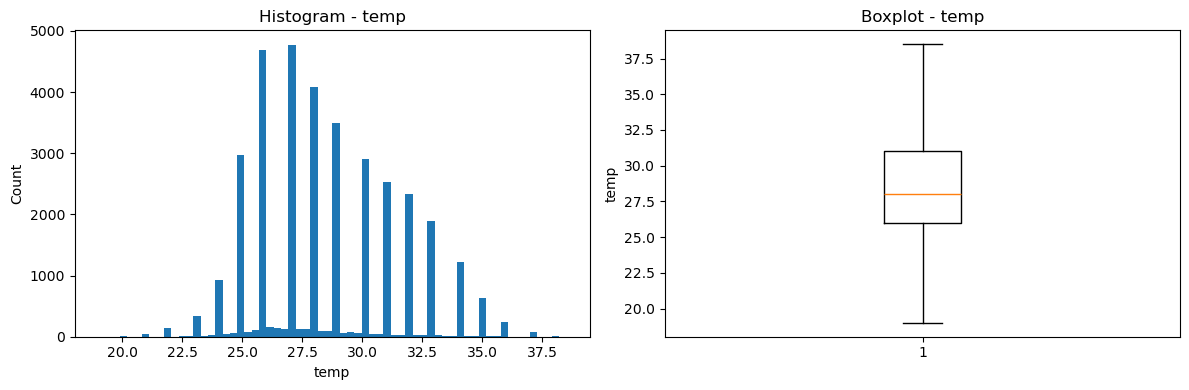

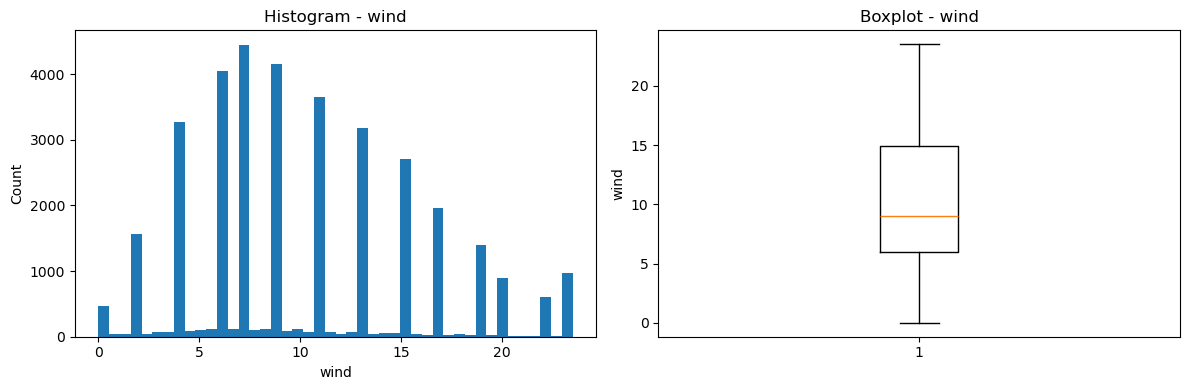

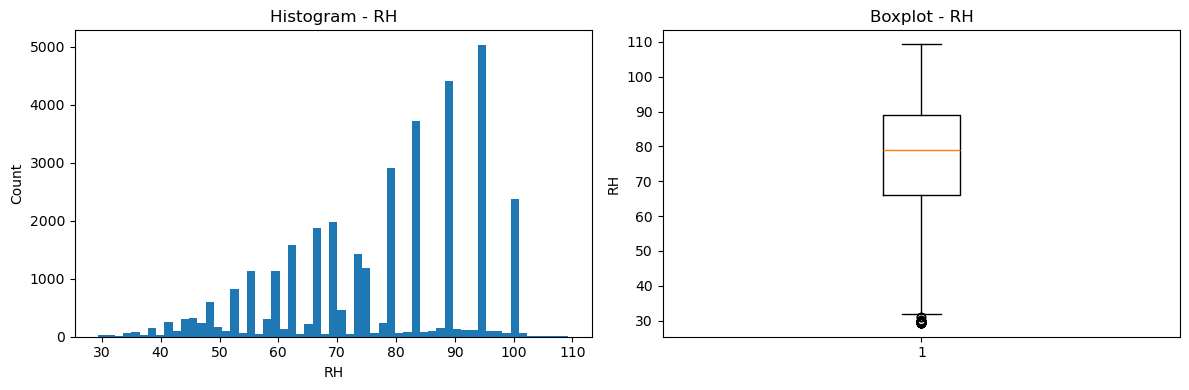

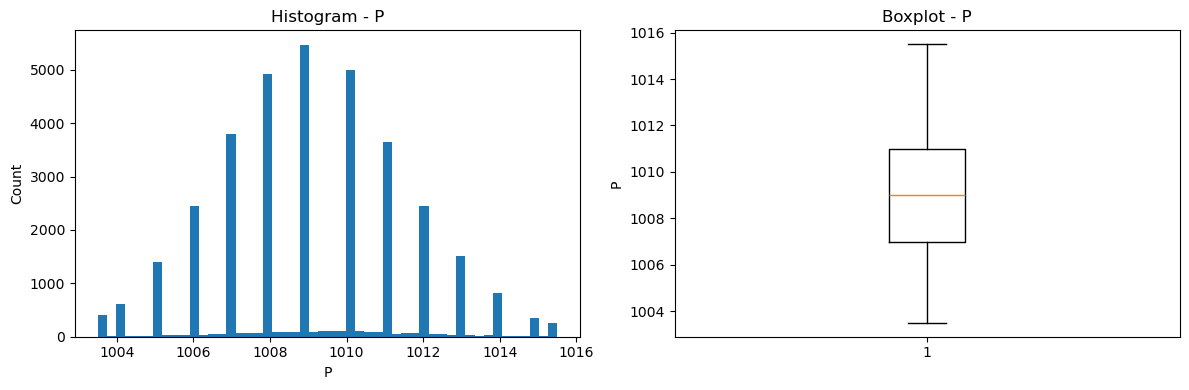

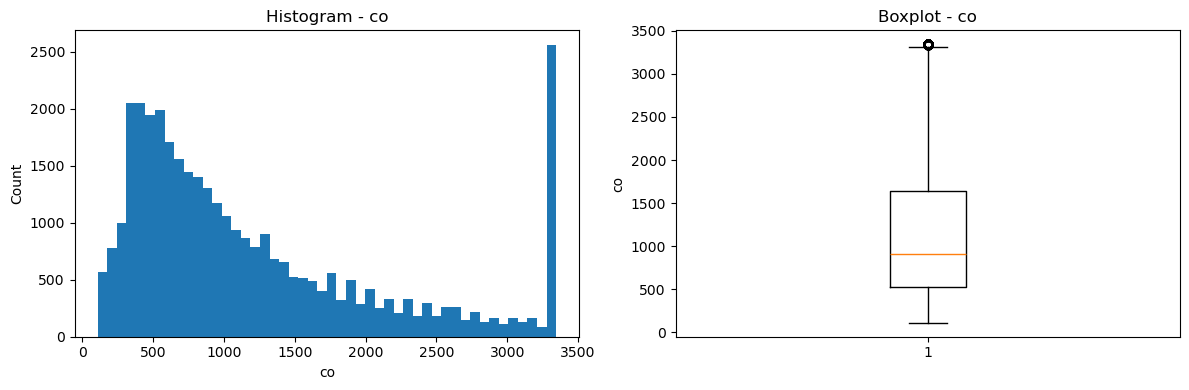

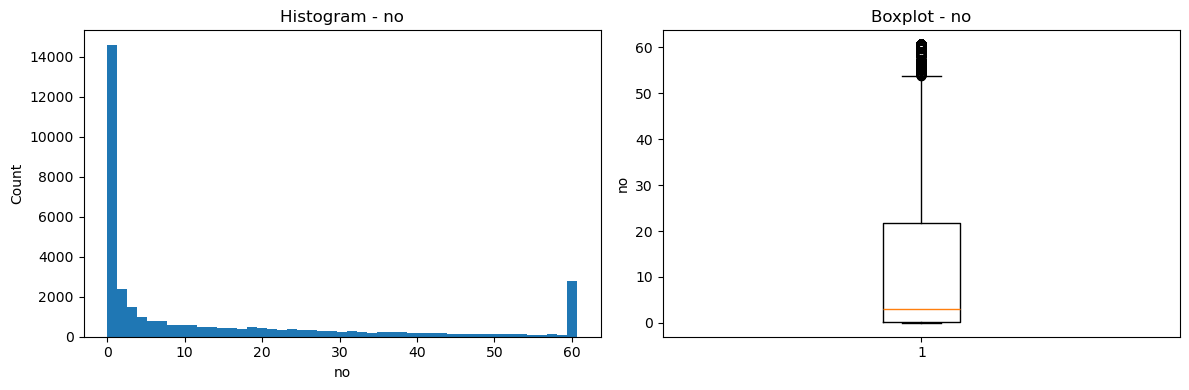

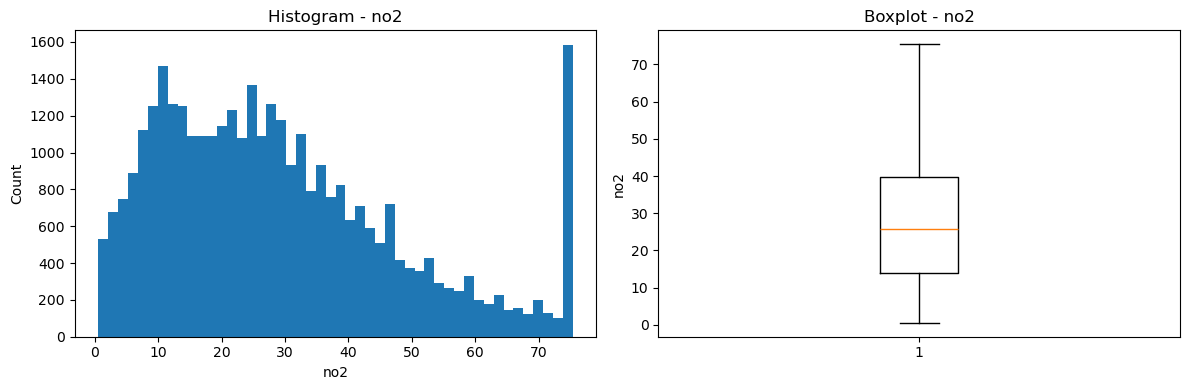

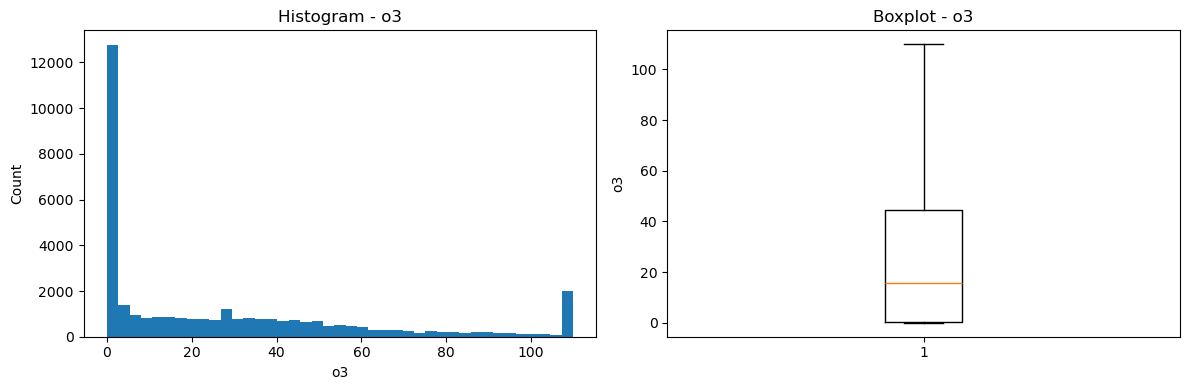

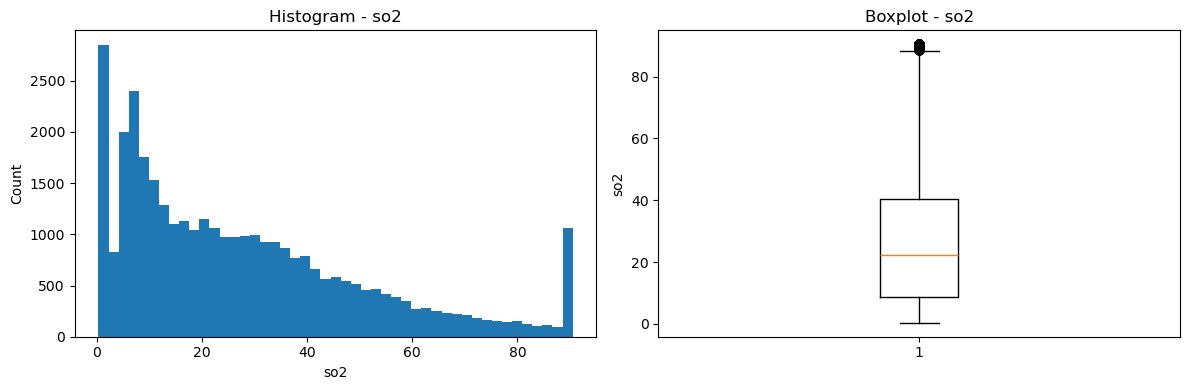

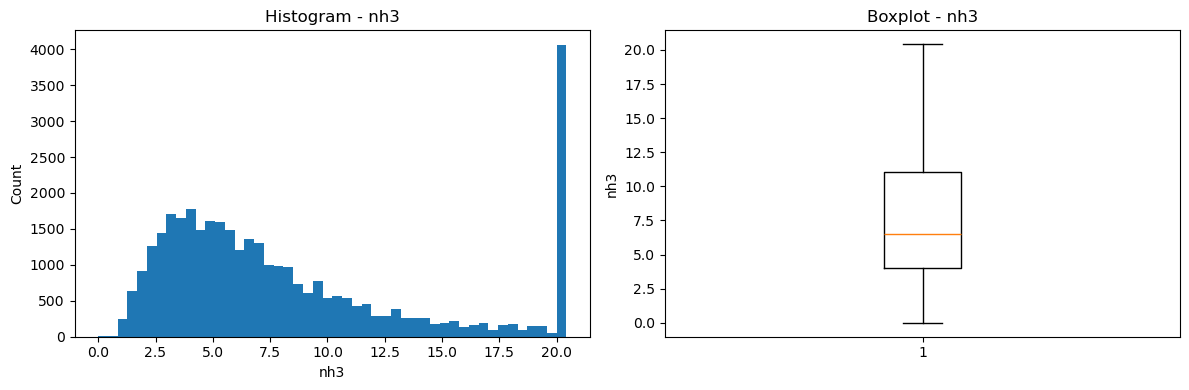

In [41]:
import matplotlib.pyplot as plt

for col in num_col:
    if col not in data_cleaned.columns:
        continue

    data = data_cleaned[col].dropna()
    if data.empty:
        continue

    plt.figure(figsize=(12, 4))

    # Histogram
    plt.subplot(1, 2, 1)
    plt.hist(data, bins='auto')
    plt.title(f'Histogram - {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

    # Boxplot
    plt.subplot(1, 2, 2)
    plt.boxplot(data, vert=True)
    plt.title(f'Boxplot - {col}')
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()


In [42]:
data = pd.read_csv(r'..\2. Exploratory Data Analyst\Data_HasTarget_NotPreocess.csv')

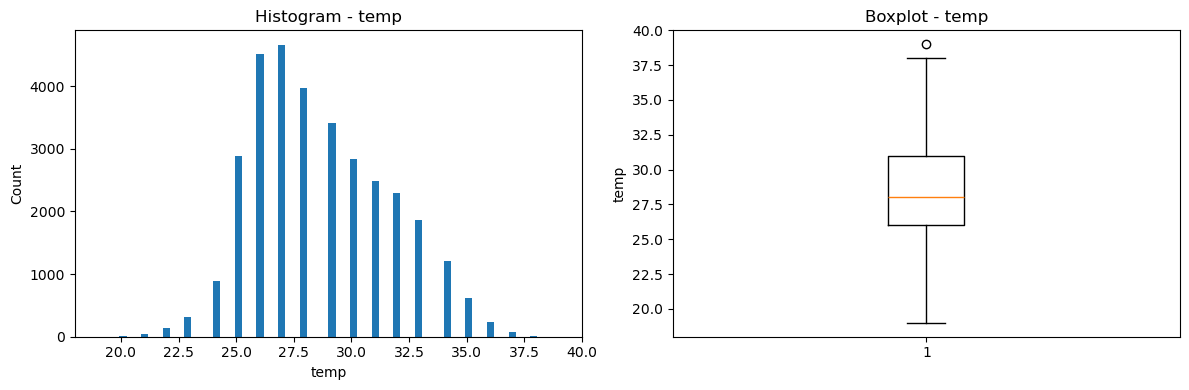

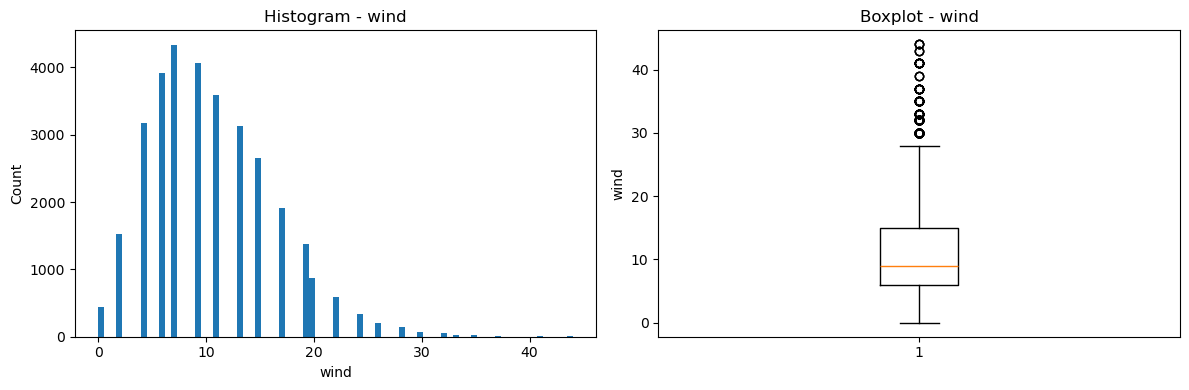

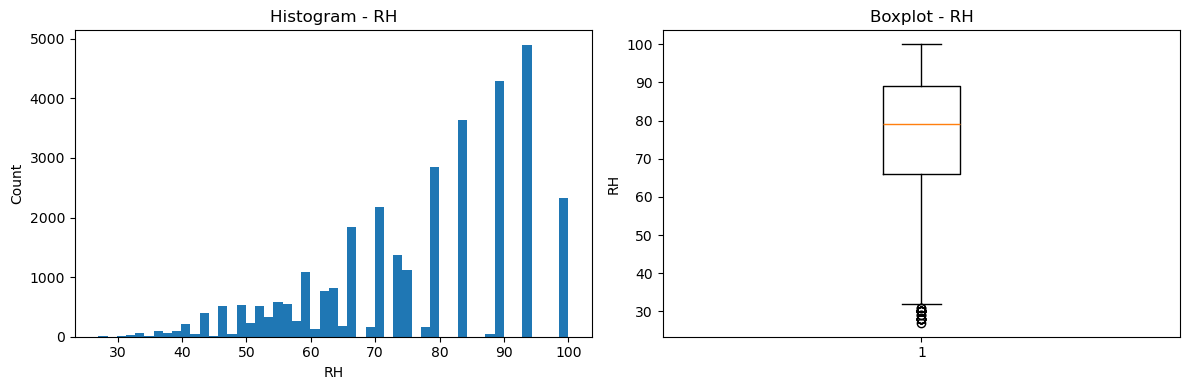

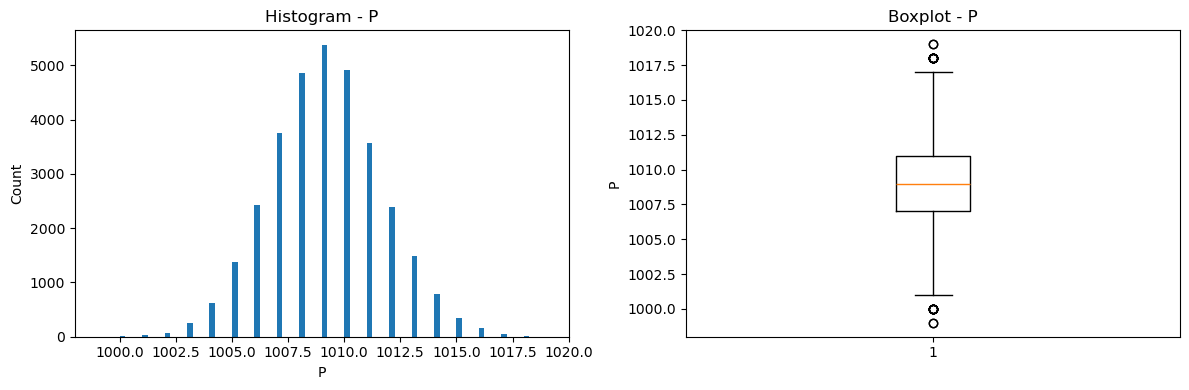

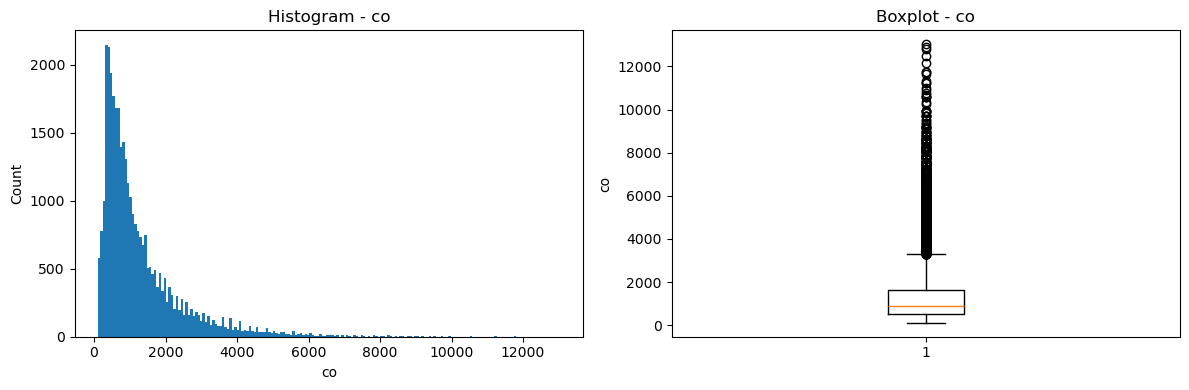

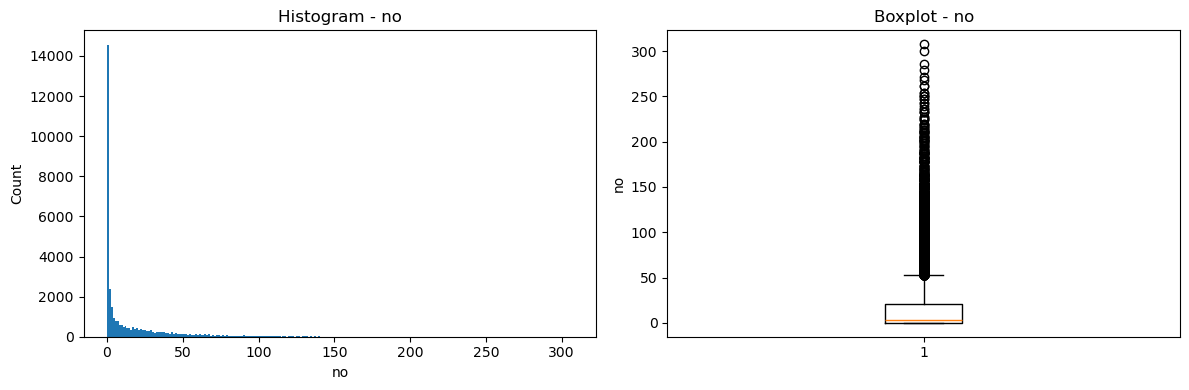

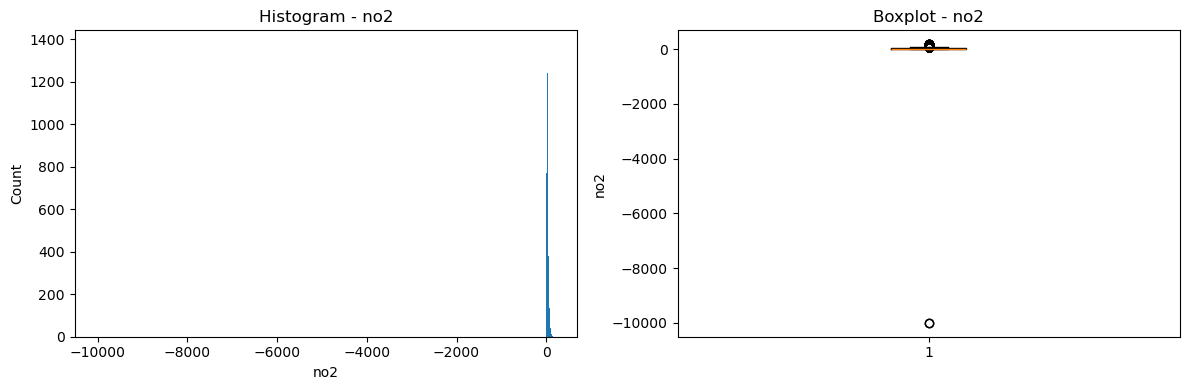

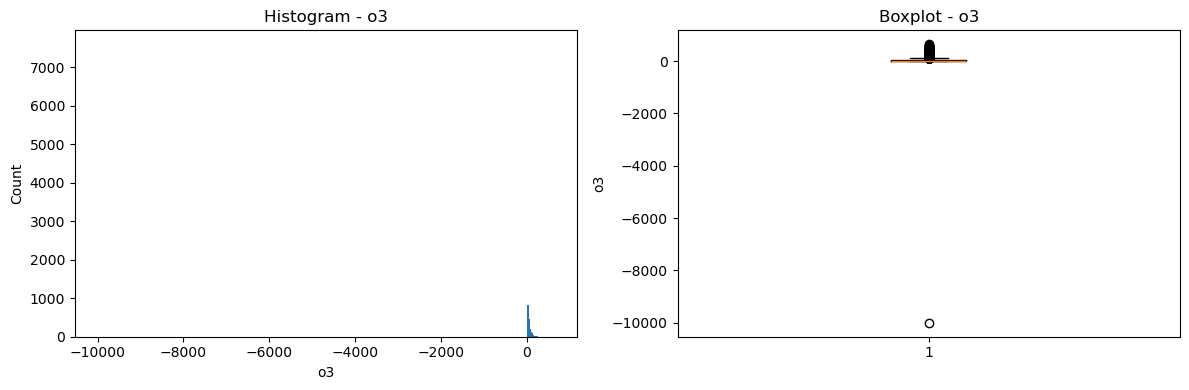

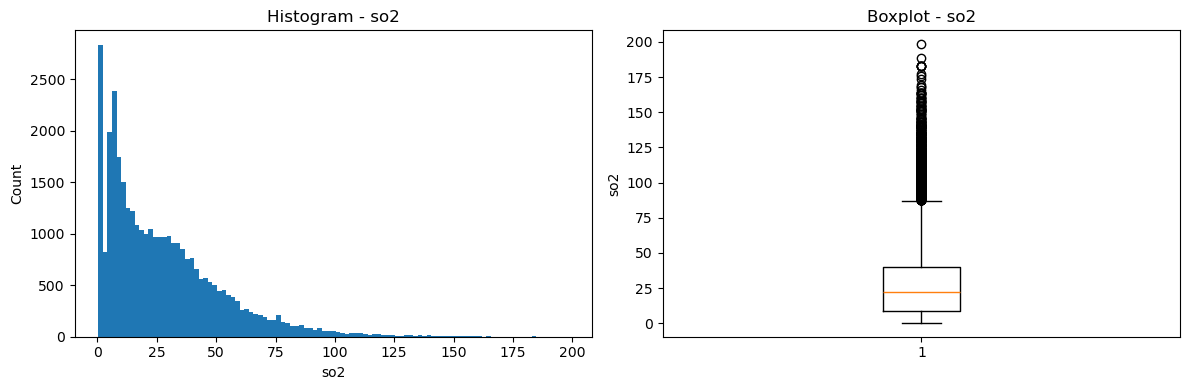

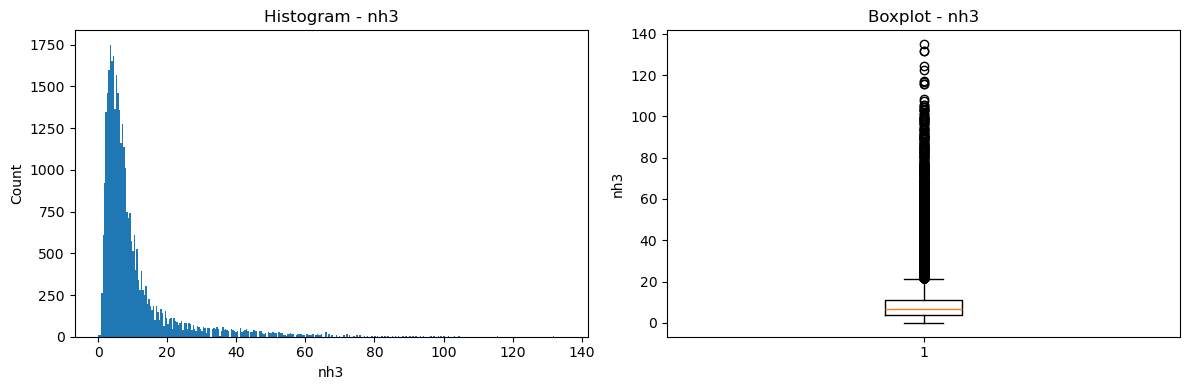

In [43]:
import matplotlib.pyplot as plt

for col in num_col:

    temp = data[col].dropna()
    if data.empty:
        continue

    plt.figure(figsize=(12, 4))

    # Histogram
    plt.subplot(1, 2, 1)
    plt.hist(temp, bins='auto')
    plt.title(f'Histogram - {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

    # Boxplot
    plt.subplot(1, 2, 2)
    plt.boxplot(temp, vert=True)
    plt.title(f'Boxplot - {col}')
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()
